# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Rifky Aflah Fauzan
- NIM   : 241011401493
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [3]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 93    # 2 digit terakhir NIM 241011401493

In [4]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    """Membagi data menjadi training dan testing secara acak (diimplementasikan dengan NumPy)."""
    X = np.asarray(X)
    y = np.asarray(y)
    n = X.shape[0]

    rng = np.random.RandomState(random_state)
    indices = rng.permutation(n)            # acak urutan indeks

    n_test = int(round(n * test_size))      # jumlah data testing
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


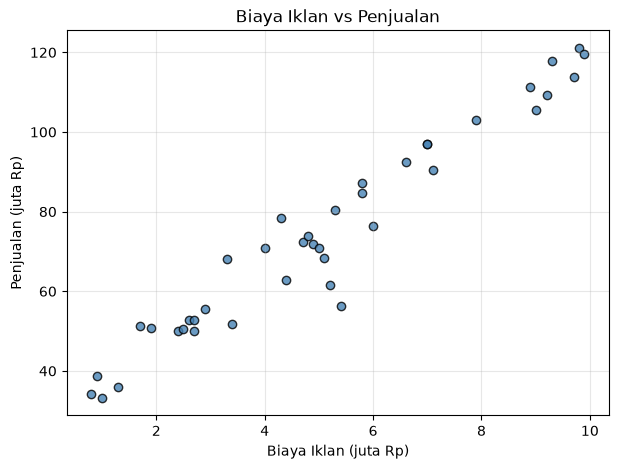

In [5]:
# Jawaban A1
# 1. Baca data, tampilkan 5 data pertama dan jumlah baris
df_ads = pd.read_csv("Ads_Data.csv")
print("5 data pertama:")
display(df_ads.head())
print("Jumlah baris data:", df_ads.shape[0])

# 2. Pisahkan X dan y (X harus 2 dimensi -> (n, 1))
X = df_ads[["BiayaIklan"]].values      # kurung siku ganda => shape (n, 1)
y = df_ads["Penjualan"].values         # shape (n,)
print("Shape X:", X.shape, "| Shape y:", y.shape)

# 3. Scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(X, y, color="steelblue", edgecolor="k", alpha=0.8)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [7]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X_b = np.c_[np.ones(X.shape[0]), X]                 # tambah kolom bias (1)
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y     # normal equation
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_


# 1. Training
lin_reg = LinearRegression().fit(X_train, y_train)

# 2. Intercept, koefisien, dan persamaan garis
b = lin_reg.intercept_
m = lin_reg.coef_[0]
print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan     : y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b) : 28.9612
Koefisien (m) : 8.9352
Persamaan     : y_hat = 28.9612 + 8.9352 * X


**Jawaban A3 (interpretasi):**

Koefisien biaya iklan sebesar **8,9352** berarti, menurut model, setiap kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan penjualan yang diperkirakan sekitar **Rp8,94 juta**. Intercept **28,9612** adalah nilai penjualan yang diperkirakan saat biaya iklan Rp0 juta; karena nilai tersebut berada di luar kisaran data yang diamati (Rp0,8–Rp9,9 juta), interpretasikan dengan hati-hati.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [8]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

hasil_eval = pd.DataFrame({
    "Training": [mae(y_train, y_pred_train), mse(y_train, y_pred_train),
                 rmse(y_train, y_pred_train), r2_score(y_train, y_pred_train)],
    "Testing":  [mae(y_test, y_pred_test), mse(y_test, y_pred_test),
                 rmse(y_test, y_pred_test), r2_score(y_test, y_pred_test)],
}, index=["MAE", "MSE", "RMSE", "R2"])

display(hasil_eval.round(4))

,Training,Testing
MAE,4.2628,5.8367
MSE,33.8516,45.9860
RMSE,5.8182,6.7813
R2,0.9382,0.9399


**Jawaban A4 (analisis):**

Pada data testing, RMSE sebesar **6,7813 juta Rp** berarti besar kesalahan prediksi tipikal berada di sekitar Rp6,78 juta. Nilai R² testing **0,9399** menunjukkan model menjelaskan sekitar 93,99% variasi penjualan pada data testing. Karena metrik testing dekat dengan training (RMSE 5,8182 dan R² 0,9382), performa model tampak baik dan tidak menunjukkan kesenjangan besar antara data latih dan uji; tetap ada error prediksi dan hasil ini hanya mewakili dataset kecil tersebut.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Normal Equation -> intercept = 28.9612, koefisien = 8.9352

GD lr=0.001  -> intercept = 25.9814, koefisien = 9.4297, loss akhir = 35.8551
GD lr=0.02   -> intercept = 28.9612, koefisien = 8.9352, loss akhir = 33.8516
GD lr=0.1    -> intercept = nan, koefisien = nan, loss akhir = nan


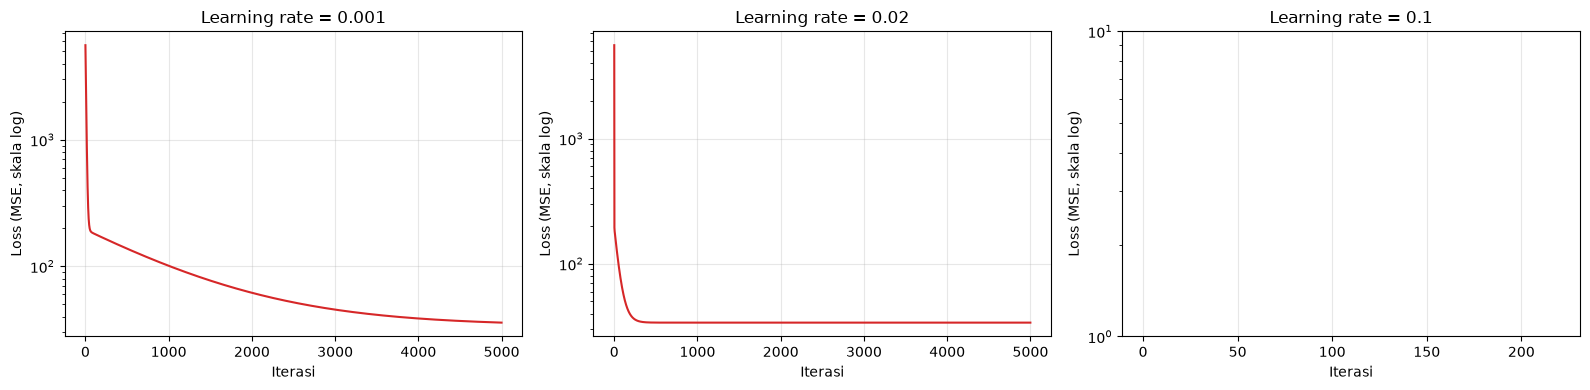

In [9]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = None
        self.coef_ = None
        self.losses_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(d)
        self.losses_ = []

        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y

            # gradient dari MSE
            grad_b = (2 / n) * np.sum(error)
            grad_m = (2 / n) * (X.T @ error)

            # update parameter
            self.intercept_ -= self.learning_rate * grad_b
            self.coef_ -= self.learning_rate * grad_m

            self.losses_.append(np.mean(error ** 2))   # simpan loss (MSE)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_


learning_rates = [0.001, 0.02, 0.1]
models_gd = {}

# 1 & 2. Training untuk tiap learning rate + bandingkan dengan normal equation
print(f"Normal Equation -> intercept = {lin_reg.intercept_:.4f}, koefisien = {lin_reg.coef_[0]:.4f}\n")
with np.errstate(all="ignore"):     # overflow pada LR besar adalah bagian dari eksperimen
    for lr in learning_rates:
        gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
        models_gd[lr] = gd
        print(f"GD lr={lr:<6} -> intercept = {gd.intercept_:.4f}, koefisien = {gd.coef_[0]:.4f}, "
              f"loss akhir = {gd.losses_[-1]:.4f}")

# 3. Grafik loss vs iterasi (skala log)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
with np.errstate(all="ignore"):
    for ax, lr in zip(axes, learning_rates):
        ax.plot(models_gd[lr].losses_, color="tab:red")
        ax.set_yscale("log")
        ax.set_title(f"Learning rate = {lr}")
        ax.set_xlabel("Iterasi")
        ax.set_ylabel("Loss (MSE, skala log)")
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Learning rate **0,001** terlalu lambat untuk 5.000 iterasi: loss akhirnya **35,8551**, masih di atas MSE normal equation **33,8516**, dan parameternya (intercept 25,9814; koefisien 9,4297) belum tepat konvergen. Learning rate **0,02** pas pada eksperimen ini karena mencapai intercept **28,9612**, koefisien **8,9352**, dan loss **33,8516**, yang cocok dengan solusi normal equation. Learning rate **0,1** terlalu besar sehingga langkah pembaruan melewati minimum berulang kali; nilai parameter dan loss menjadi `nan` (divergen/overflow). Besar learning rate perlu disesuaikan dengan skala fitur dan gradien.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

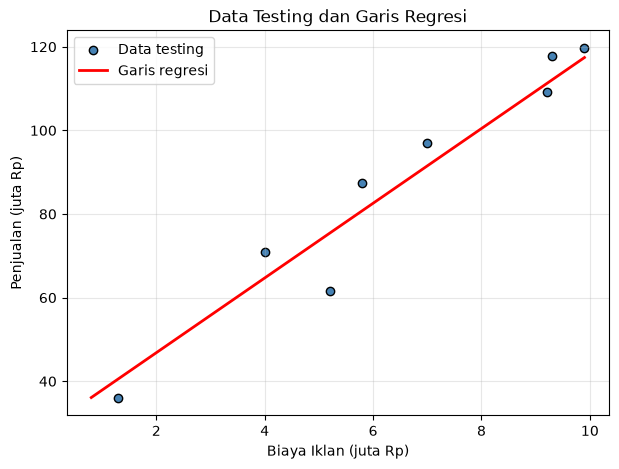

,BiayaIklan (juta),Prediksi Penjualan (juta),Keterangan
0,4.5,69.17,Interpolasi
1,7.0,91.51,Interpolasi
2,12.0,136.18,Ekstrapolasi (di luar rentang data)


Rentang BiayaIklan pada data: 0.8 - 9.9 juta


In [10]:
# Jawaban A6
# 1. Scatter data testing + garis regresi (normal equation)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color="steelblue", edgecolor="k", label="Data testing")
plt.plot(x_line, lin_reg.predict(x_line), color="red", linewidth=2, label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi untuk biaya iklan 4.5, 7, dan 12 juta
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi = lin_reg.predict(biaya_baru)
df_prediksi = pd.DataFrame({
    "BiayaIklan (juta)": biaya_baru.ravel(),
    "Prediksi Penjualan (juta)": prediksi.round(2),
    "Keterangan": ["Interpolasi", "Interpolasi", "Ekstrapolasi (di luar rentang data)"],
})
display(df_prediksi)
print(f"Rentang BiayaIklan pada data: {X.min()} - {X.max()} juta")

**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan Rp4,5 juta dan Rp7 juta masing-masing **Rp69,17 juta** dan **Rp91,51 juta**; keduanya interpolasi karena masih berada dalam rentang biaya iklan yang diamati (Rp0,8–Rp9,9 juta). Prediksi Rp12 juta adalah ekstrapolasi sebesar **Rp136,18 juta**, sehingga kurang dapat dipercaya: model mengasumsikan hubungan linear terus berlaku di luar data, padahal pola sebenarnya dapat berubah.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email Spam (1)       : 25
Jumlah email Bukan Spam (0) : 35
Shape X: (60, 2) | Shape y: (60,)


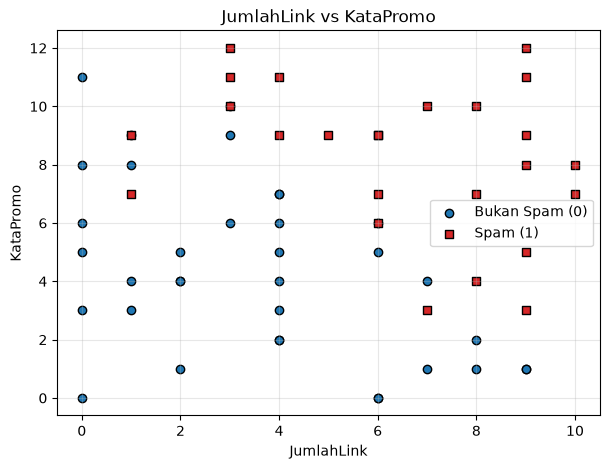

In [11]:
# Jawaban B1
# 1. Baca data, 5 data pertama, dan jumlah tiap kelas
df_email = pd.read_csv("Email_Data.csv")
print("5 data pertama:")
display(df_email.head())
print("Jumlah email Spam (1)       :", (df_email["Spam"] == 1).sum())
print("Jumlah email Bukan Spam (0) :", (df_email["Spam"] == 0).sum())

# 2. Pisahkan X dan y
X_email = df_email[["JumlahLink", "KataPromo"]].values
y_email = df_email["Spam"].values
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

# 3. Scatter plot dengan warna berbeda per kelas
plt.figure(figsize=(7, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1],
            color="tab:blue", edgecolor="k", label="Bukan Spam (0)")
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1],
            color="tab:red", edgecolor="k", marker="s", label="Spam (1)")
plt.title("JumlahLink vs KataPromo")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape Xe_train: (45, 2) | Xe_test: (15, 2)
Intercept (b) : -8.8517
Koefisien m1  : 0.7563  (JumlahLink)
Koefisien m2  : 0.7258  (KataPromo)
P(Spam) = sigmoid(-8.8517 + 0.7563 * JumlahLink + 0.7258 * KataPromo)


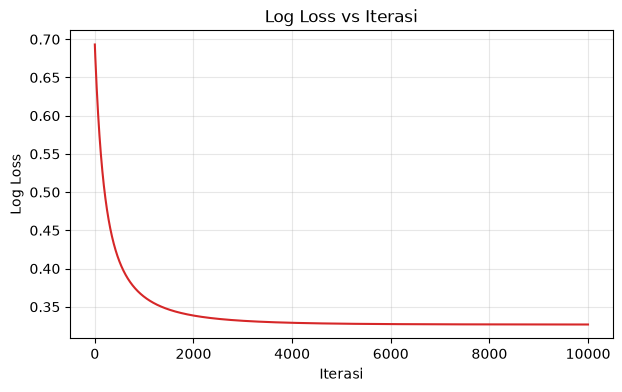

Log loss awal = 0.6931 | akhir = 0.3268


In [12]:
# Jawaban B2
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))   # clip agar tidak overflow

class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss / binary cross-entropy)."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = None
        self.coef_ = None
        self.losses_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(d)
        self.losses_ = []
        eps = 1e-15

        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coef_)

            # log loss
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.losses_.append(loss)

            # gradient
            error = p - y
            grad_b = np.mean(error)
            grad_m = (X.T @ error) / n

            # update parameter
            self.intercept_ -= self.learning_rate * grad_b
            self.coef_ -= self.learning_rate * grad_m
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


# 1. Split data (test_size = 0.25)
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print("Shape Xe_train:", Xe_train.shape, "| Xe_test:", Xe_test.shape)

# 2. Training
log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)

# 3. Intercept, koefisien, dan persamaan
b0 = log_reg.intercept_
m1, m2 = log_reg.coef_
print(f"Intercept (b) : {b0:.4f}")
print(f"Koefisien m1  : {m1:.4f}  (JumlahLink)")
print(f"Koefisien m2  : {m2:.4f}  (KataPromo)")
print(f"P(Spam) = sigmoid({b0:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(7, 4))
plt.plot(log_reg.losses_, color="tab:red")
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(alpha=0.3)
plt.show()
print(f"Log loss awal = {log_reg.losses_[0]:.4f} | akhir = {log_reg.losses_[-1]:.4f}")

**Jawaban B2 (analisis):**

Log loss turun dari **0,6931** menjadi **0,3268**, jadi model belajar lebih baik daripada tebakan awal berprobabilitas 0,5. Pada grafik, penurunan kemudian mendatar, menandakan loss mulai stabil. Model yang diperoleh adalah `P(Spam) = sigmoid(-8,8517 + 0,7563 × JumlahLink + 0,7258 × KataPromo)`; kedua koefisien positif, sehingga kenaikan masing-masing fitur menaikkan skor spam ketika fitur lain tetap.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [13]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Return matriks 2x2: [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

# Evaluasi pada data testing (threshold 0.5)
ye_pred = log_reg.predict(Xe_test)

cm = confusion_matrix(ye_test, ye_pred)
print("Accuracy :", round(accuracy_score(ye_test, ye_pred), 4))
print("Precision:", round(precision_score(ye_test, ye_pred), 4))
print("Recall   :", round(recall_score(ye_test, ye_pred), 4))
print("F1-score :", round(f1_score(ye_test, ye_pred), 4))
print("\nConfusion Matrix:")
display(pd.DataFrame(cm,
                     index=["Aktual: Bukan Spam", "Aktual: Spam"],
                     columns=["Prediksi: Bukan Spam", "Prediksi: Spam"]))
print(f"TN={cm[0,0]} | FP={cm[0,1]} | FN={cm[1,0]} | TP={cm[1,1]}")

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Confusion Matrix:


,Prediksi: Bukan Spam,Prediksi: Spam
Aktual: Bukan Spam,6,0
Aktual: Spam,0,9


TN=6 | FP=0 | FN=0 | TP=9


**Jawaban B3 (analisis):**

Pada data testing, confusion matrix menghasilkan **TN=6, FP=0, FN=0, TP=9**, sehingga accuracy, precision, recall, dan F1 semuanya **1,0**. FP berarti email bukan spam keliru ditandai sebagai spam; FN berarti email spam lolos sebagai bukan spam. Keduanya merugikan: FP dapat menyembunyikan email penting, sedangkan FN membiarkan spam masuk. Untuk penggunaan umum, FN dapat lebih berisiko bila spam berisi tautan berbahaya, tetapi pada data ini tidak ada satu pun dari kedua jenis kesalahan tersebut.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-8.8517 + 0.7563 * x1) / 0.7258
                   x2 = 12.1958 + (-1.0420) * x1


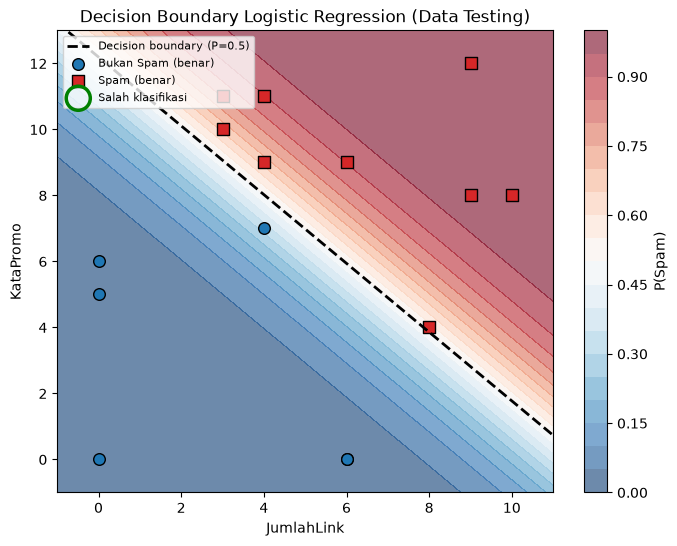

Jumlah data testing yang salah klasifikasi: 0 dari 15


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)


In [14]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f"Decision boundary: x2 = -({b0:.4f} + {m1:.4f} * x1) / {m2:.4f}")
print(f"                   x2 = {-b0/m2:.4f} + ({-m1/m2:.4f}) * x1")

# 2. Visualisasi: background probabilitas + garis decision boundary
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                       np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx1.ravel(), xx2.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(xx1.shape)

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, prob_grid, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")

x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b0 + m1 * x1_line) / m2
plt.plot(x1_line, x2_line, "k--", linewidth=2, label="Decision boundary (P=0.5)")

# 3. Data testing + tandai yang salah klasifikasi
benar = (ye_pred == ye_test)
plt.scatter(Xe_test[(ye_test == 0) & benar, 0], Xe_test[(ye_test == 0) & benar, 1],
            c="tab:blue", edgecolor="k", s=70, label="Bukan Spam (benar)")
plt.scatter(Xe_test[(ye_test == 1) & benar, 0], Xe_test[(ye_test == 1) & benar, 1],
            c="tab:red", edgecolor="k", s=70, marker="s", label="Spam (benar)")
salah = ~benar
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=300, facecolors="none",
            edgecolors="green", linewidths=2.5, label="Salah klasifikasi")

plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.title("Decision Boundary Logistic Regression (Data Testing)")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend(loc="upper left", fontsize=8)
plt.show()

# Daftar data testing yang salah diklasifikasikan
df_salah = pd.DataFrame({
    "JumlahLink": Xe_test[salah, 0],
    "KataPromo": Xe_test[salah, 1],
    "Aktual": ye_test[salah],
    "Prediksi": ye_pred[salah],
    "P(Spam)": log_reg.predict_proba(Xe_test[salah]).round(4),
})
print(f"Jumlah data testing yang salah klasifikasi: {salah.sum()} dari {len(ye_test)}")
display(df_salah)

**Jawaban B4 (analisis):**

Garis batas keputusan yang diperoleh adalah `KataPromo = 12,1958 − 1,0420 × JumlahLink`; di atas batas model cenderung memprediksi spam (probabilitas ≥0,5). Pada data testing, **0 dari 15 email** salah diklasifikasikan, jadi tidak ada titik yang perlu ditandai sebagai salah pada grafik maupun baris pada tabel kesalahan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [15]:
# Jawaban B5
proba_test = log_reg.predict_proba(Xe_test)

baris = []
for th in [0.3, 0.5, 0.7]:
    pred_th = (proba_test >= th).astype(int)
    cm_th = confusion_matrix(ye_test, pred_th)
    baris.append({
        "Threshold": th,
        "TN": cm_th[0, 0], "FP": cm_th[0, 1],
        "FN": cm_th[1, 0], "TP": cm_th[1, 1],
        "Precision": round(precision_score(ye_test, pred_th), 4),
        "Recall": round(recall_score(ye_test, pred_th), 4),
    })

df_threshold = pd.DataFrame(baris).set_index("Threshold")
display(df_threshold)

,TN,FP,FN,TP,Precision,Recall
Threshold,,,,,,
0.3,5,1,0,9,0.9,1.0000
0.5,6,0,0,9,1.0,1.0000
0.7,6,0,3,6,1.0,0.6667


**Jawaban B5 (analisis):**

Menurunkan threshold menjadi **0,3** membuat model lebih mudah menyebut email sebagai spam: recall tetap **1,0**, tetapi muncul **1 FP** dan precision turun menjadi **0,9**. Pada threshold **0,5**, precision dan recall sama-sama **1,0** (TN=6, FP=0, FN=0, TP=9). Menaikkan threshold ke **0,7** mempertahankan precision **1,0**, tetapi recall turun menjadi **0,6667** karena ada **3 FN**. Saya memilih **0,5** untuk data ini karena tidak menghasilkan FP atau FN pada set uji; pilihan tersebut sebaiknya dievaluasi ulang pada data yang lebih besar.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [16]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.5    # sesuaikan dengan threshold yang Anda pilih di Soal B5

email_baru = np.array([[1, 2],     # E1
                       [5, 6],     # E2
                       [9, 10],    # E3
                       [2, 11]])   # E4

proba_baru = log_reg.predict_proba(email_baru)
kelas_baru = (proba_baru >= THRESHOLD_PILIHAN).astype(int)

df_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": email_baru[:, 0],
    "KataPromo": email_baru[:, 1],
    "P(Spam)": proba_baru.round(4),
    "Prediksi": np.where(kelas_baru == 1, "Spam", "Bukan Spam"),
})
print(f"Threshold yang dipakai: {THRESHOLD_PILIHAN}")
display(df_baru)

Threshold yang dipakai: 0.5


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0013,Bukan Spam
1,E2,5,6,0.3284,Bukan Spam
2,E3,9,10,0.9946,Spam
3,E4,2,11,0.6558,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut klasifikasi karena menghasilkan probabilitas kelas dan mengubahnya menjadi label, misalnya spam atau bukan spam, dengan threshold. Fungsi sigmoid memetakan skor linear apa pun ke rentang 0 sampai 1. Nilai tersebut dapat dibaca sebagai probabilitas kelas positif.

**Jawaban C2:** Normal equation menghitung parameter langsung melalui operasi matriks, tanpa proses iterasi; cara ini sederhana untuk fitur yang jumlahnya sedikit. Gradient descent memperbarui parameter berulang kali berdasarkan gradien loss dan learning rate. Gradient descent lebih sesuai untuk dataset atau jumlah fitur yang besar ketika operasi matriks langsung mahal, tetapi learning rate dan jumlah iterasinya perlu dipilih dengan baik.

**Jawaban C3:** Data testing dipakai untuk memperkirakan kinerja model pada data baru yang tidak digunakan saat pelatihan. Nilai training saja dapat terlihat bagus karena model telah menyesuaikan diri dengan data tersebut. Overfitting terjadi saat model terlalu mengikuti detail atau noise pada data training sehingga kinerjanya memburuk pada data baru.

**Jawaban C4:** Linear Regression memprediksi nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai prediksi dan target. Logistic Regression memprediksi probabilitas kelas, sehingga log loss menilai probabilitas yang diberikan kepada label sebenarnya. Log loss memberi penalti besar ketika model sangat yakin tetapi prediksinya salah.

**Jawaban C5:** Hasil dapat berbeda jika pembagian data training-testing, `random_state`, inisialisasi, learning rate, jumlah iterasi, threshold, atau pengaturan regularisasi berbeda. Pada tugas ini, `random_state` menentukan data mana yang menjadi training dan testing, sehingga koefisien dan metrik evaluasi dapat berubah. Perbedaan implementasi dan toleransi konvergensi juga dapat berpengaruh.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

# Linear Regression: gunakan pembagian data yang sama dengan implementasi NumPy
sk_lin = SklearnLinearRegression().fit(X_train, y_train)
sk_y_pred = sk_lin.predict(X_test)
print("Linear Regression (scikit-learn)")
print(f"Intercept: {sk_lin.intercept_:.4f} | Koefisien: {sk_lin.coef_[0]:.4f}")
print(f"MAE: {mae(y_test, sk_y_pred):.4f} | MSE: {mse(y_test, sk_y_pred):.4f} | "
      f"RMSE: {rmse(y_test, sk_y_pred):.4f} | R2: {r2_score(y_test, sk_y_pred):.4f}")

# Logistic Regression memakai regularisasi L2 default scikit-learn (C=1.0)
sk_log = SklearnLogisticRegression(C=1.0, max_iter=10000, random_state=RANDOM_STATE)
sk_log.fit(Xe_train, ye_train)
sk_ye_pred = sk_log.predict(Xe_test)
sk_cm = confusion_matrix(ye_test, sk_ye_pred)
print("\nLogistic Regression (scikit-learn, L2, C=1.0)")
print(f"Intercept: {sk_log.intercept_[0]:.4f} | Koefisien: "
      f"JumlahLink={sk_log.coef_[0, 0]:.4f}, KataPromo={sk_log.coef_[0, 1]:.4f}")
print(f"Accuracy: {accuracy_score(ye_test, sk_ye_pred):.4f} | "
      f"Precision: {precision_score(ye_test, sk_ye_pred):.4f} | "
      f"Recall: {recall_score(ye_test, sk_ye_pred):.4f} | "
      f"F1: {f1_score(ye_test, sk_ye_pred):.4f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
display(pd.DataFrame(sk_cm,
                     index=["Aktual: Bukan Spam", "Aktual: Spam"],
                     columns=["Prediksi: Bukan Spam", "Prediksi: Spam"]))

**Jawaban Bonus (analisis):**

Hasil scikit-learn untuk Linear Regression sama dengan implementasi normal equation: intercept **28,9612**, koefisien **8,9352**, dan R² testing **0,9399**. Pada Logistic Regression, koefisien scikit-learn (intercept **−8,2416**, JumlahLink **0,6985**, KataPromo **0,6742**) berbeda dari implementasi gradient descent (−8,8517; 0,7563; 0,7258), tetapi keduanya mencapai accuracy **1,0** dan confusion matrix **[[6, 0], [0, 9]]**. Perbedaan terutama karena scikit-learn menerapkan regularisasi L2 secara default (`C=1.0`), sedangkan model buatan sendiri tidak memakai regularisasi, serta optimizer dan kriteria konvergensinya berbeda.